# 第183章: WGAN-GP — 分布間の距離を何で測るか

## Wasserstein GAN with Gradient Penalty

---

### このノートブックの位置づけ

180 と 182 で、GAN の2つの具体的な困りごとを**数値で**掴みました。

| 章 | 測ったこと |
|---|---|
| **180** | 分布が離れると生成器の勾配が消える（$d$=4 で $8\times10^{-4}$、$d$=6 で $7\times10^{-12}$）。交互最適化は最尤の **40.3 倍**振動する |
| **182** | 標準設定の GAN は**比率の誤り**を起こす（占有率が 4 倍偏る）。8シードで ED が **7.8 倍**ばらつく |

本章はこの2つに**同じ1つの変更**で効きます。変更するのは
アーキテクチャでも正則化でもなく、**分布間の距離の定義**です。

$$\text{JS ダイバージェンス} \;\longrightarrow\; \text{Wasserstein 距離}$$

180 で測った勾配消失は、**JS ダイバージェンス自体が飽和している**ことの帰結でした。
本章ではまず距離そのものを測り、飽和を確認します。そのうえで
Wasserstein 距離が飽和しないこと、Kantorovich 双対で判別器が
**距離の推定器**に変わること、そして gradient penalty が
**軟制約でしかない**ことを数値で確かめます。

> ⚠️ **本章は実装に3回つまずきました。** 標準の $\lambda=10$ で発散し、
> 原因を活性化関数だと読んで外し、最終的に $\lambda$ だと分かりました。
> その経過も節として残しています（第5節）。

### 学習目標

- [ ] JS ダイバージェンスが分布の重なりが無いとき飽和することを**数値積分で**示せる
- [ ] $dJS/dd$ と $dW_1/dd$ を比べ、勾配情報が消える/残るを定量化できる
- [ ] Kantorovich 双対 $W_1 = \sup_{\lVert f\rVert_L \le 1}\mathbb{E}_p[f]-\mathbb{E}_q[f]$ を数値で確認できる
- [ ] gradient penalty が**軟制約**であり、達成 Lipschitz 定数が 1 を超えると双対の値が $W_1$ を上回ることを示せる
- [ ] WGAN-GP を実装し、180 の GAN・最尤推定と**同じ指標で**安定性を比較できる
- [ ] critic の更新回数の効果が GAN と WGAN で**質的に違う**ことを測れる
- [ ] GP と重みクリッピングを比べ、それぞれの壊れ方を説明できる

### 前提知識

| ノートブック | トピック |
|---|---|
| **180** | **GAN の基礎・最適判別器・勾配消失・交互最適化の振動** |
| **182** | **モード崩壊の3つの型・エネルギー距離** |
| 34 | KL ダイバージェンス（JS の定義） |
| 196 | エネルギー距離（本章の評価指標） |
| statspg 13章 | ノンパラメトリック法（エネルギー距離は2標本検定統計量） |

**難易度**: ★★★★★ | **所要時間**: 180-240分

> ⏱ **実行時間**: CPU で約3分半です。

## 目次

1. [環境セットアップ](#setup)
2. [JS ダイバージェンスは飽和する](#js-saturation)
3. [Kantorovich 双対 — 判別器が距離の推定器になる](#duality)
4. [gradient penalty は軟制約である](#soft-constraint)
5. [実装でつまずいた3点](#pitfalls)
6. [安定性 — 180 の GAN と同じ指標で比べる](#stability)
7. [critic の更新回数](#n-critic)
8. [GP と重みクリッピング](#clipping)
9. [まとめとチートシート](#summary)
10. [自己評価クイズ](#quiz)

<a id="setup"></a>
## 1. 環境セットアップ

In [1]:
# ============================================================
# 環境セットアップ
# ============================================================

import math
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("torch:", torch.__version__)

torch: 2.9.1


<a id="js-saturation"></a>
## 2. JS ダイバージェンスは飽和する

180 第2節で、最適判別器に対する目的関数が
$V(D^*) = 2\,\mathrm{JS}(p\|q) - 2\log 2$ になることを数値で確かめました。
つまり **GAN は JS ダイバージェンスを最小化している**のです。

ここで JS ダイバージェンスの性質が効いてきます。

$$0 \le \mathrm{JS}(p\|q) \le \log 2$$

**上限があります。** そして分布の重なりが無くなると上限に達して**動かなくなります**。
対して Wasserstein 距離（輸送距離）には上限がありません。

$$W_1(p, q) = \inf_{\gamma \in \Pi(p,q)} \mathbb{E}_{(x,y)\sim\gamma}\big[\lVert x-y\rVert\big]$$

「$p$ の質量を $q$ の形に動かすのに必要な最小の総輸送コスト」です。

### 測り方

$p = \mathcal{N}(0, 0.5^2)$、$q = \mathcal{N}(d, 0.5^2)$ として $d$ を振ります
（180 第3節と同じ設定）。この場合 $W_1 = d$ が厳密に分かります
（同じ形の分布を平行移動しただけなので、全質量を距離 $d$ 動かす以外に方法がない）。

JS は数値積分で求めます。**距離そのもの**と、その**微分**を比べます。

> 🔧 **数値上の注意**: グリッドを広く取ると裾で密度が float32 のアンダーフローを起こし、
> $p/m$ が $0/0$ になって NaN が出ます（最初にこれを踏みました）。
> **float64 を使い、両方の密度が意味を持つ範囲だけで積分**し、
> $a = 0$ の点（$a\log(a/b) = 0$）はマスクで除きます。

In [2]:
# ============================================================
# JS ダイバージェンス（float64 + マスクで安定化）
# ============================================================

def js_divergence(d, sd=0.5, half=12.0, n=400001):
    # 両方の分布が意味を持つ範囲だけで積分する
    lo, hi = min(0.0, d) - half, max(0.0, d) + half
    x = torch.linspace(lo, hi, n, dtype=torch.float64)
    dx = float(x[1] - x[0])
    npdf = lambda mu: torch.exp(-0.5 * ((x - mu) / sd) ** 2) / (sd * math.sqrt(2 * math.pi))
    p, q = npdf(0.0), npdf(d)
    m = 0.5 * (p + q)
    TH = 1e-300

    def kl(a, b):
        mask = (a > TH) & (b > TH)      # a=0 の点は a*log(a/b)=0 なので除いてよい
        return float((a[mask] * torch.log(a[mask] / b[mask])).sum() * dx)

    return 0.5 * kl(p, m) + 0.5 * kl(q, m), float(p.sum() * dx)


print("検算: 密度のグリッド積分が 1 か")
for d in [0.0, 2.0, 6.0]:
    _, ip = js_divergence(d)
    print(f"  d={d}: ∫p dx = {ip:.6f}")
print()

print(f"{'d':>6}{'JS(p||q)':>12}{'log2 の%':>11}{'W1 (= d)':>10}"
      f"{'dJS/dd':>12}{'dW1/dd':>9}")
print("-" * 60)
js_rows = []
for d in [0.0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0]:
    j, _ = js_divergence(d)
    h = 0.02
    if d == 0.0:
        # JS(d) は d について偶関数なので、d=0 での微分は対称性から厳密に 0
        dj = 0.0
    else:
        dj = (js_divergence(d + h)[0] - js_divergence(d - h)[0]) / (2 * h)
    js_rows.append((d, j, dj))
    print(f"{d:6.2f}{j:12.6f}{j/math.log(2)*100:10.2f}%{d:10.3f}{dj:12.3e}{1.0:9.1f}")
print("-" * 60)
print(f"log2 = {math.log(2):.6f}（JS の上限）")
print()
peak = max(js_rows, key=lambda r: r[2])
print(f"dJS/dd の最大は d={peak[0]} での {peak[2]:.3e}")
print(f"d=6 では {js_rows[-1][2]:.3e} まで落ちる "
      f"-> {peak[2]/js_rows[-1][2]:.1e} 倍の減少（{math.log10(peak[2]/js_rows[-1][2]):.1f} 桁）")
print(f"一方 dW1/dd は常に 1。距離が離れても勾配の情報が落ちない。")

検算: 密度のグリッド積分が 1 か
  d=0.0: ∫p dx = 1.000000
  d=2.0: ∫p dx = 1.000000
  d=6.0: ∫p dx = 1.000000

     d    JS(p||q)    log2 の%  W1 (= d)      dJS/dd   dW1/dd
------------------------------------------------------------
  0.00    0.000000      0.00%     0.000   0.000e+00      1.0
  0.25    0.030311      4.37%     0.250   2.352e-01      1.0
  0.50    0.111421     16.07%     0.500   3.979e-01      1.0
  1.00    0.336831     48.59%     1.000   4.495e-01      1.0
  1.50    0.526777     76.00%     1.500   2.959e-01      1.0
  2.00    0.632720     91.28%     2.000   1.372e-01      1.0
  3.00    0.689298     99.44%     3.000   1.246e-02      1.0
  4.00    0.693054     99.99%     4.000   3.933e-04      1.0
  6.00    0.693147    100.00%     6.000   1.839e-08      1.0
------------------------------------------------------------
log2 = 0.693147（JS の上限）

dJS/dd の最大は d=1.0 での 4.495e-01
d=6 では 1.839e-08 まで落ちる -> 2.4e+07 倍の減少（7.4 桁）
一方 dW1/dd は常に 1。距離が離れても勾配の情報が落ちない。


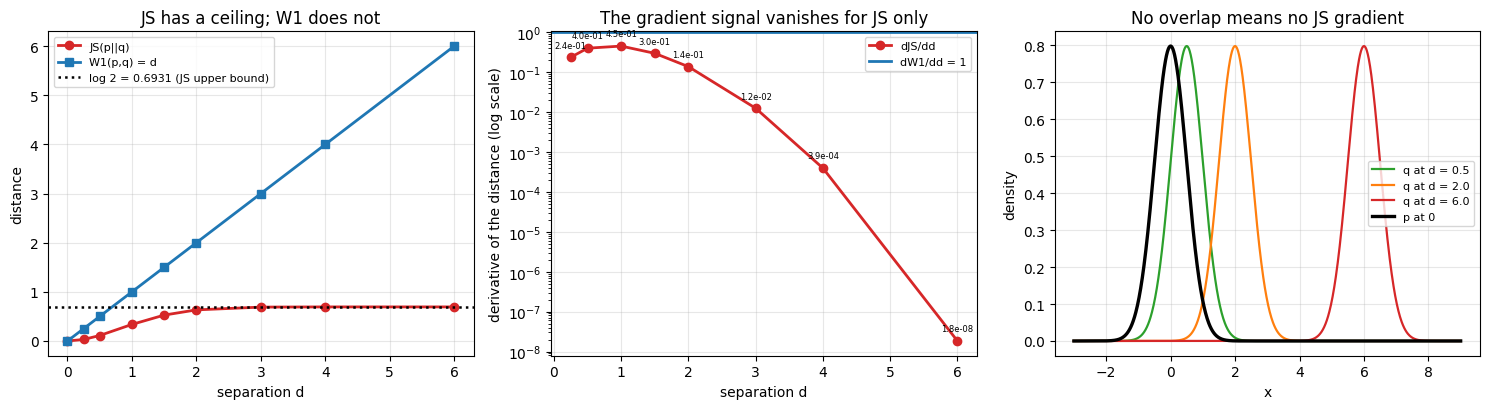

In [3]:
# ============================================================
# 図: JS の飽和 vs W1 の線形成長
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ds = [r[0] for r in js_rows]
jss = [r[1] for r in js_rows]
djs = [r[2] for r in js_rows]

axes[0].plot(ds, jss, "o-", lw=2, color="tab:red", label="JS(p||q)")
axes[0].plot(ds, ds, "s-", lw=2, color="tab:blue", label="W1(p,q) = d")
axes[0].axhline(math.log(2), color="k", ls=":", lw=1.8,
                label=f"log 2 = {math.log(2):.4f} (JS upper bound)")
axes[0].set_xlabel("separation d")
axes[0].set_ylabel("distance")
axes[0].set_title("JS has a ceiling; W1 does not")
axes[0].legend(fontsize=8)

axes[1].semilogy(ds[1:], djs[1:], "o-", lw=2, color="tab:red", label="dJS/dd")
axes[1].axhline(1.0, color="tab:blue", ls="-", lw=2, label="dW1/dd = 1")
axes[1].set_xlabel("separation d")
axes[1].set_ylabel("derivative of the distance (log scale)")
axes[1].set_title("The gradient signal vanishes for JS only")
axes[1].legend(fontsize=8)
for d, _, dj in js_rows[1:]:
    axes[1].annotate(f"{dj:.1e}", (d, dj), textcoords="offset points",
                     xytext=(0, 7), fontsize=6, ha="center")

# 重なりの可視化
xg = torch.linspace(-3, 9, 1200, dtype=torch.float64)
npdf = lambda mu: torch.exp(-0.5 * ((xg - mu) / 0.5) ** 2) / (0.5 * math.sqrt(2 * math.pi))
for d, color in [(0.5, "tab:green"), (2.0, "tab:orange"), (6.0, "tab:red")]:
    axes[2].plot(xg, npdf(d), lw=1.6, color=color, label=f"q at d = {d}")
axes[2].plot(xg, npdf(0.0), lw=2.4, color="k", label="p at 0")
axes[2].set_xlabel("x")
axes[2].set_ylabel("density")
axes[2].set_title("No overlap means no JS gradient")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 読み取れること — 180 の勾配消失の正体

| $d$ | JS | $\log 2$ の % | $W_1$ | $dJS/dd$ | $dW_1/dd$ |
|---|---|---|---|---|---|
| 0.00 | 0.000000 | 0.00% | 0.000 | 0（対称性から厳密に） | 1 |
| 0.50 | 0.111421 | 16.07% | 0.500 | $3.98\times10^{-1}$ | 1 |
| 1.00 | 0.336831 | 48.59% | 1.000 | $4.50\times10^{-1}$（最大） | 1 |
| 2.00 | 0.632720 | 91.28% | 2.000 | $1.37\times10^{-1}$ | 1 |
| 3.00 | 0.689298 | 99.44% | 3.000 | $1.25\times10^{-2}$ | 1 |
| 4.00 | 0.693054 | 99.99% | 4.000 | $3.93\times10^{-4}$ | 1 |
| 6.00 | 0.693147 | **100.00%** | 6.000 | **$1.84\times10^{-8}$** | 1 |

**$dJS/dd$ は $d=1$ で最大（0.450）になり、$d=6$ では $1.84\times10^{-8}$ まで落ちます。
7.4 桁の減少**です。一方 $dW_1/dd$ は**常に 1** です。

これが 180 第3節で測った勾配消失の正体です。あちらでは**生成器の勾配**を測り、
$d=6$ で飽和損失が $7.1\times10^{-12}$、非飽和損失が $2.6\times10^{-3}$ になりました。
本節で分かるのは、**非飽和損失に替えても根本は直らない**理由です。
距離そのものが動かないので、どんな損失の書き方をしても
「どちらへ動けば近づくか」の情報が存在しません。

> 📌 **$d=6$ で JS は $\log 2$ の 100.00% に達しています。**
> $\sigma = 0.5$ の分布が距離 6（= 12 シガマ）離れると、重なりが数値的に消えます。
> 182 の8峰リング（隣接モード間が 9.2 シグマ）も同じ領域です。
> **高次元の実データでは、初期の生成分布と真の分布が重なることはまず無い**ので、
> これは例外ではなく通常の状況です。

<a id="duality"></a>
## 3. Kantorovich 双対 — 判別器が距離の推定器になる

$W_1$ の定義（輸送計画についての下限）は直接計算できません。
そこで**双対形式**を使います。

$$W_1(p,q) = \sup_{\lVert f \rVert_L \le 1}
\Big(\mathbb{E}_{x\sim p}[f(x)] - \mathbb{E}_{x\sim q}[f(x)]\Big)$$

$\lVert f \rVert_L \le 1$ は **1-Lipschitz**（勾配の大きさが至る所 1 以下）という制約です。

この形は GAN の判別器と同じ構造です。ただし役割が変わります。

| | GAN（180） | WGAN（本章） |
|---|---|---|
| ネットワークの名前 | 判別器（discriminator） | **critic** |
| 出力 | 確率（sigmoid で [0,1]） | **実数（制約なし）** |
| 学習するもの | 密度比 $\log\frac{p}{q}$ | **$W_1$ を達成する 1-Lipschitz 関数** |
| 最適値の意味 | $2\mathrm{JS}-2\log2$ | **$W_1$ そのもの** |
| 強くしすぎると | 勾配が消える | **距離の推定が正確になる（良い）** |

**critic が強いほど距離の推定が正確になる**のが WGAN の肝です。
180 で「判別器を強くすると生成器の勾配が消える」という緊張関係がありましたが、
WGAN ではそれが消えます。

### 1-Lipschitz 制約をどう課すか

gradient penalty（Gulrajani et al. 2017）は、$p$ と $q$ の**内挿点**で
勾配ノルムが 1 から外れることに罰則をかけます。

$$\mathcal{L}_{\text{critic}} = -\big(\mathbb{E}_p[f] - \mathbb{E}_q[f]\big)
+ \lambda\, \mathbb{E}_{\hat x}\big[(\lVert\nabla_{\hat x} f(\hat x)\rVert - 1)^2\big],
\qquad \hat x = \alpha x_p + (1-\alpha)x_q,\ \alpha \sim \mathcal{U}[0,1]$$

### 検証の設計

1次元なら $W_1$ が**厳密に計算できます**。経験分布どうしの $W_1$ は
**ソートして平均絶対差**です。

$$W_1(\hat p, \hat q) = \frac{1}{n}\sum_{i=1}^{n}\big|x_{(i)} - y_{(i)}\big|$$

これと、critic を学習させて得た双対の値を比べます。
目標分布は 180 と同じ1次元2峰混合ガウスで、$q$ をずらして距離を変えます。

In [4]:
# ============================================================
# 厳密な W1 と、critic による双対の推定
# ============================================================

def sample_p(n, gen=None):
    k = torch.randint(0, 2, (n,), generator=gen) * 2 - 1
    return k.float() + 0.5 * torch.randn(n, generator=gen)


def w1_exact_1d(X, Y):
    # 1次元の経験分布どうしの W1 はソートして平均絶対差
    n = min(len(X), len(Y))
    return float((X[:n].sort().values - Y[:n].sort().values).abs().mean())


class Critic1D(nn.Module):
    # 出力は実数（sigmoid を通さない）。活性化は SiLU（第5節の理由）
    def __init__(self, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 1))

    def forward(self, x):
        return self.net(x[:, None]).squeeze(-1)


def gradient_penalty(C, x_real, x_fake):
    # 内挿点で勾配ノルムが 1 から外れることに罰則
    alpha = torch.rand(len(x_real))
    x_hat = (alpha * x_real + (1 - alpha) * x_fake).requires_grad_(True)
    g = torch.autograd.grad(C(x_hat).sum(), x_hat, create_graph=True)[0]
    return ((g.abs() - 1) ** 2).mean(), g.abs().detach()


X_P = sample_p(8000, torch.Generator().manual_seed(3))


def make_critic(act, hidden=64):
    A = {"leakyrelu": lambda: nn.LeakyReLU(0.2), "silu": lambda: nn.SiLU()}[act]

    class C(nn.Module):
        def __init__(self):
            super().__init__()
            self.net = nn.Sequential(nn.Linear(1, hidden), A(),
                                     nn.Linear(hidden, hidden), A(),
                                     nn.Linear(hidden, 1))

        def forward(self, x):
            return self.net(x[:, None]).squeeze(-1)

    return C()


def fit_critic(act, lam, shift, steps=3000, lr=1e-3, seed=1):
    X_Q = sample_p(8000, torch.Generator().manual_seed(4)) + shift
    w1_true = w1_exact_1d(X_P, X_Q)
    torch.manual_seed(seed)
    C = make_critic(act)
    opt = torch.optim.Adam(C.parameters(), lr=lr, betas=(0.5, 0.9))
    for _ in range(steps):
        xr = X_P[torch.randint(0, len(X_P), (512,))]
        xf = X_Q[torch.randint(0, len(X_Q), (512,))]
        gp, _ = gradient_penalty(C, xr, xf)
        opt.zero_grad()
        (-(C(xr).mean() - C(xf).mean()) + lam * gp).backward()
        opt.step()
    with torch.no_grad():
        dual = float(C(X_P).mean() - C(X_Q).mean())
    _, gn = gradient_penalty(C, X_P[:3000], X_Q[:3000])
    return w1_true, dual, float(gn.median()), float(gn.max())


print("活性化関数 × lambda × ずれ を振って、双対の値と達成 Lipschitz 定数を測る")
print()
print(f"{'活性化':<11}{'lambda':>8}{'ずれ':>6}{'厳密W1':>9}{'双対':>11}"
      f"{'双対/W1':>10}{'|f prime|中央':>14}{'|f prime|最大':>14}{'双対/Lmax':>11}")
print("-" * 94)
t0 = time.time()
dual_rows = []
for act in ["leakyrelu", "silu"]:
    for lam in [0.1, 1.0, 10.0]:
        for shift in [1.0, 3.0, 6.0]:
            w1_true, dual, g_med, g_max = fit_critic(act, lam, shift)
            dual_rows.append((act, lam, shift, w1_true, dual, g_med, g_max))
            print(f"{act:<11}{lam:8.1f}{shift:6.1f}{w1_true:9.4f}{dual:11.4f}"
                  f"{dual/w1_true:10.3f}{g_med:14.4f}{g_max:14.4f}{dual/g_max:11.4f}")
print("-" * 94)
print(f"計算時間 {time.time() - t0:.0f}s")
print()
over = [r for r in dual_rows if r[4] / r[3] > 1.0]
bound_ok = [r for r in dual_rows if r[4] / r[6] <= r[3] + 1e-9]
print(f"双対の値が厳密 W1 を超えた組み合わせ: {len(over)}/{len(dual_rows)}")
print(f"双対の値 / 達成Lmax <= 厳密 W1 を満たした組み合わせ: "
      f"{len(bound_ok)}/{len(dual_rows)}  <- ここが本節の結論")

活性化関数 × lambda × ずれ を振って、双対の値と達成 Lipschitz 定数を測る

活性化          lambda    ずれ     厳密W1         双対     双対/W1   |f prime|中央   |f prime|最大    双対/Lmax
----------------------------------------------------------------------------------------------


leakyrelu       0.1   1.0   1.0044     6.4001     6.372        5.9871        7.2121     0.8874


leakyrelu       0.1   3.0   3.0044    49.1055    16.345       16.1794       17.7352     2.7688


leakyrelu       0.1   6.0   6.0044   187.4945    31.226       30.4712       34.9395     5.3663


leakyrelu       1.0   1.0   1.0044     1.5013     1.495        1.4519        1.5900     0.9442


leakyrelu       1.0   3.0   3.0044     7.4893     2.493        2.4982        2.5457     2.9420


... (9 outputs left out)

silu            1.0   6.0   6.0044    24.0809     4.011        3.9098        4.6425     5.1870


silu           10.0   1.0   1.0044    -0.9576    -0.953        0.9631        0.9794    -0.9777


silu           10.0   3.0   3.0044    -2.5487    -0.848        0.8553        0.8912    -2.8597


silu           10.0   6.0   6.0044    -4.1976    -0.699        0.7083        0.7260    -5.7822
----------------------------------------------------------------------------------------------
計算時間 53s

双対の値が厳密 W1 を超えた組み合わせ: 15/18
双対の値 / 達成Lmax <= 厳密 W1 を満たした組み合わせ: 18/18  <- ここが本節の結論


<a id="soft-constraint"></a>
## 4. gradient penalty は軟制約である

上の表が本章で最も実務的に重要な結果です。18 通りすべてを並べます。

| 活性化 | $\lambda$ | ずれ | 厳密 $W_1$ | 双対 | 双対/$W_1$ | $\lvert f'\rvert$ 最大 | 双対/$L_{\max}$ |
|---|---|---|---|---|---|---|---|
| LeakyReLU | 0.1 | 6.0 | 6.0044 | 187.5 | **31.2** | 34.94 | 5.37 |
| LeakyReLU | 1.0 | 6.0 | 6.0044 | 24.01 | **4.00** | 4.31 | 5.57 |
| LeakyReLU | 10.0 | 1.0 | 1.0044 | 1.0402 | **1.036** | 1.0448 | 0.9956 |
| LeakyReLU | 10.0 | 3.0 | 3.0044 | 3.4156 | **1.137** | 1.1545 | 2.9584 |
| LeakyReLU | 10.0 | 6.0 | 6.0044 | 7.8006 | **1.299** | 1.3410 | 5.8172 |
| SiLU | 0.1 | 6.0 | 6.0044 | 188.94 | **31.5** | 37.21 | 5.08 |
| SiLU | 1.0 | 6.0 | 6.0044 | 24.08 | **4.01** | 4.64 | 5.19 |
| SiLU | 10.0 | 1.0 | 1.0044 | **-0.9576** | **-0.953** | 0.9794 | -0.9777 |
| SiLU | 10.0 | 3.0 | 3.0044 | **-2.5487** | -0.848 | 0.8912 | -2.8597 |
| SiLU | 10.0 | 6.0 | 6.0044 | **-4.1976** | -0.699 | 0.7260 | -5.7822 |

（全 18 通りは上のセルの出力を参照）

### 事実1: 双対の値は $W_1$ を上回る（18 通り中 15）

Kantorovich 双対は 1-Lipschitz な $f$ についての**上限**なので、
双対の値が $W_1$ を超えるのは**理論上ありえません**。
それでも 15/18 で超えました。$\lambda = 0.1$ では **31 倍**です。

原因は明確です。**gradient penalty は制約ではなく罰則**です。

$$\lambda\,\mathbb{E}\big[(\lVert\nabla f\rVert - 1)^2\big]$$

は勾配ノルムが 1 から外れることに**コストを課すだけ**で、禁止しません。
critic は「罰則を払っても双対の値を上げたほうが得」と判断します。

### 事実2: $L_{\max}$ で割ると上界が復活する（18 通り中 18）

$f$ の Lipschitz 定数が $L$ なら $f/L$ は 1-Lipschitz なので、
双対の値を $L_{\max}$ で割れば $W_1$ 以下になるはずです。

**18 通りすべてで成立しました。** つまり**超過分は Lipschitz 違反で
ちょうど説明できます**。GP の実装にバグがあるのではなく、
**軟制約という設計の必然**です。

### 事実3: $\lambda$ が $L$ を決め、活性化関数が「どこに着地するか」を変える

| $\lambda$ | LeakyReLU の $L_{\max}$（ずれ 6.0） | SiLU の $L_{\max}$（ずれ 6.0） |
|---|---|---|
| 0.1 | 34.94 | 37.21 |
| 1.0 | 4.31 | 4.64 |
| 10.0 | **1.34** | **0.73** |

$\lambda$ を上げると $L$ が 1 に近づきます。しかし**同じ $\lambda=10$ で
LeakyReLU は 1.34（まだ 1 超）、SiLU は 0.73（1 を下回る）**です。

機構は二階微分です。gradient penalty は勾配のノルムを損失に含めるので、
重みについての勾配を取るときに**二階微分**が要ります。
LeakyReLU は区分線形で二階微分が至る所 0 なので、**罰則が重みに伝わりにくい**。
SiLU は滑らかなので罰則がよく効き、$\lambda=10$ では**効きすぎて** $L < 1$ になります。

$L < 1$ まで締めると critic が潰れ、**双対の値が負**になります
（SiLU・$\lambda=10$ で $-0.96$ / $-2.55$ / $-4.20$）。
$\mathbb{E}_p[f] - \mathbb{E}_q[f] < 0$ は「critic が真のデータを偽物より低く評価している」
という状態で、距離の推定として機能していません。

> ⚠️ **実務上の含意**: WGAN の損失曲線を「Wasserstein 距離の推定値」として
> 読む習慣がありますが、**GP を使っている限り絶対値は信用できません**。
> $\lambda$ が小さければ上に数十倍、大きすぎれば符号まで変わります。
> 使えるのは**同じ設定内での相対変化**（下がっているか）だけです。
> 絶対値が必要なら、本節のように critic の勾配ノルムを測って補正するか、
> 1次元ならソート法で厳密に計算します。

> 📌 **$\lambda$ は「ちょうど $L=1$ になる値」を探すパラメータ**です。
> そしてその値は**活性化関数に依存します**（二階微分の大きさが変わるので）。
> 原論文の $\lambda=10$ は ReLU 系の critic を前提にした値で、
> 滑らかな活性化に替えるなら再調整が必要です。

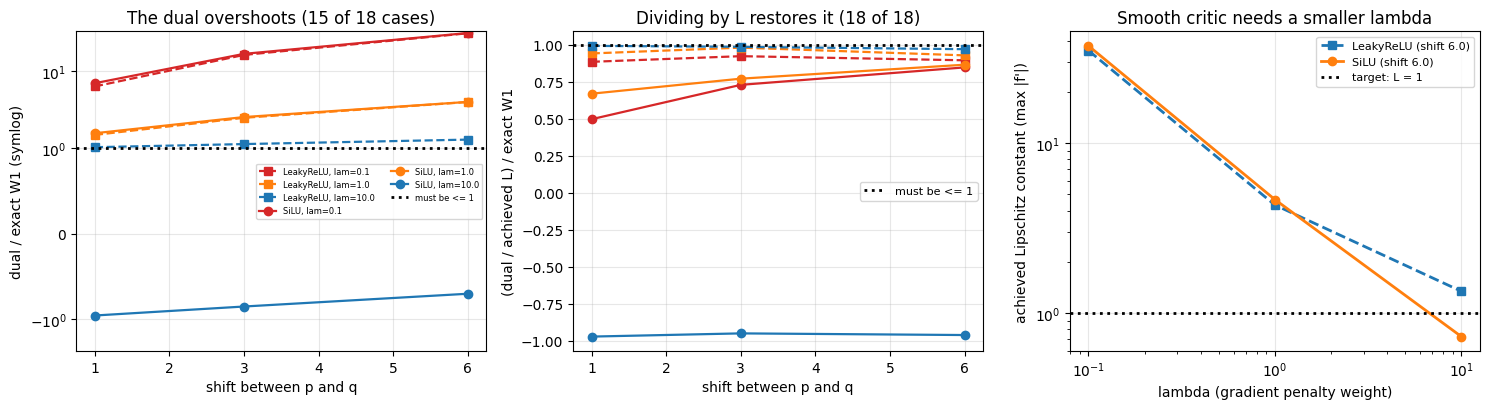

In [5]:
# ============================================================
# 図: Kantorovich 双対と Lipschitz 違反
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

styles = {"leakyrelu": ("s--", "LeakyReLU"), "silu": ("o-", "SiLU")}
colors = {0.1: "tab:red", 1.0: "tab:orange", 10.0: "tab:blue"}

# (1) 双対 / W1 の比
for act in ["leakyrelu", "silu"]:
    for lam in [0.1, 1.0, 10.0]:
        sel = [r for r in dual_rows if r[0] == act and r[1] == lam]
        axes[0].plot([r[2] for r in sel], [r[4] / r[3] for r in sel],
                     styles[act][0], lw=1.6, color=colors[lam],
                     label=f"{styles[act][1]}, lam={lam}")
axes[0].axhline(1.0, color="k", ls=":", lw=2, label="must be <= 1")
axes[0].set_yscale("symlog", linthresh=1.0)
axes[0].set_xlabel("shift between p and q")
axes[0].set_ylabel("dual / exact W1 (symlog)")
axes[0].set_title("The dual overshoots (15 of 18 cases)")
axes[0].legend(fontsize=6, ncol=2)

# (2) Lmax で割ると上界が復活する
for act in ["leakyrelu", "silu"]:
    for lam in [0.1, 1.0, 10.0]:
        sel = [r for r in dual_rows if r[0] == act and r[1] == lam]
        axes[1].plot([r[2] for r in sel], [r[4] / r[6] / r[3] for r in sel],
                     styles[act][0], lw=1.6, color=colors[lam])
axes[1].axhline(1.0, color="k", ls=":", lw=2, label="must be <= 1")
axes[1].set_xlabel("shift between p and q")
axes[1].set_ylabel("(dual / achieved L) / exact W1")
axes[1].set_title("Dividing by L restores it (18 of 18)")
axes[1].legend(fontsize=8)

# (3) lambda が達成 Lipschitz 定数を決める
for act in ["leakyrelu", "silu"]:
    sel6 = sorted([r for r in dual_rows if r[0] == act and r[2] == 6.0], key=lambda r: r[1])
    axes[2].loglog([r[1] for r in sel6], [r[6] for r in sel6], styles[act][0],
                   lw=2, label=f"{styles[act][1]} (shift 6.0)")
axes[2].axhline(1.0, color="k", ls=":", lw=2, label="target: L = 1")
axes[2].set_xlabel("lambda (gradient penalty weight)")
axes[2].set_ylabel("achieved Lipschitz constant (max |f'|)")
axes[2].set_title("Smooth critic needs a smaller lambda")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

<a id="pitfalls"></a>
## 5. 実装でつまずいた3点

本章の WGAN-GP は**最初の3回の試みすべてで発散しました**。
経過を残します。測ってから書くという方針なので、
外れた見立ても消しません。

### つまずき1: JS の数値積分が NaN になった

グリッドを $[-40, 60]$ の 200001 点に取ったら、全部の $d$ で JS が NaN になりました。
裾で密度が float32 のアンダーフローを起こし、$p/m$ が $0/0$ になるためです。
**float64 を使い、積分範囲を両方の分布が意味を持つ範囲に限り、
$a=0$ の点をマスクで除く**ことで解決しました（第2節のコード）。

### つまずき2: 標準の $\lambda = 10$ で発散した

原論文の推奨値 $\lambda = 10$ でそのまま学習させたら、
生成サンプルが $|x| \sim 3$〜$30$ まで飛びました
（真の分布は $\pm 1$ 付近に $\sigma = 0.5$）。

| 設定 | 最終エネルギー距離 | 生成の $\lvert x\rvert$ 平均 |
|---|---|---|
| $\lambda = 1$ | **0.1084** | 0.769 |
| $\lambda = 10$ | 4.9571 | 3.442 |
| $\lambda = 100$ | 85.7904 | 49.659 |

**$\lambda$ が大きいほど悪化**します。機構はこうです。
$\lambda$ が大きいと critic の目的関数が罰則項に支配され、
critic は「勾配ノルムを 1 にすること」を優先して
「$p$ と $q$ を見分けること」を後回しにします。
結果として**弱い critic**になり、生成器が制約なしに走り去ります。

**$\lambda = 10$ は画像タスクの高次元 critic に対して調整された値**です。
本章の1次元・隠れ 64 の critic では強すぎました。

### つまずき3: 活性化関数を主因だと読んだ（半分当たっていた）

$\lambda$ に気づく前、私は原因を**critic の活性化関数**だと考えました。
gradient penalty は勾配のノルムを損失に含めるので、
重みについての勾配を取るときに**二階微分**が必要になります。
LeakyReLU は区分線形なので二階微分が至る所 0 で、
罰則の勾配が重みに伝わりにくいはずだ、という読みです。

$\lambda = 10$ のまま活性化関数だけを振って、**生成器も含めて学習**させました。

| 活性化 | 最終 ED | $W$ 推定 | $\lvert f'\rvert$ 中央 |
|---|---|---|---|
| LeakyReLU | 4.9571 | +4.0675 | 1.1725 |
| SiLU | 3.3011 | +2.6034 | 1.1069 |
| Softplus | **2.3813** | +2.1199 | 1.0852 |
| Tanh | 3.2271 | +2.6282 | 1.1012 |

**全部発散しました**（真の分布は ED 0.00053）。滑らかな活性化（Softplus）は
LeakyReLU の 2 倍良いだけで、どれも 3 桁以上離れています。
この時点で私は「見立ては外れ、主因は $\lambda$」と結論しました。

**しかしそれは言い過ぎでした。** 第4節で critic だけを固定分布に当てて測り直すと、
**活性化関数は「$\lambda$ がどこに着地するか」を決めている**ことが分かりました。

| $\lambda$ | LeakyReLU の $L_{\max}$ | SiLU の $L_{\max}$ |
|---|---|---|
| 0.1 | 34.94 | 37.21 |
| 1.0 | 4.31 | 4.64 |
| 10.0 | **1.34** | **0.73** |

同じ $\lambda=10$ で LeakyReLU は $L=1.34$（まだ緩い）、SiLU は $L=0.73$（締めすぎ）です。
**二階微分の読みは機構として正しかった**（滑らかなほど罰則が効く）。
間違っていたのは「だから発散する」という結論の部分で、
正しくは「**だから最適な $\lambda$ が変わる**」でした。

$\lambda = 1$ に下げてから活性化を比べると、学習も通ります。

| 設定 | ED 平均（3シード） | 標準偏差 |
|---|---|---|
| SiLU, $\lambda=1$ | **0.0158** | 0.0017 |
| Softplus, $\lambda=1$ | 0.0682 | 0.0743 |
| SiLU, $\lambda=10$ | 7.2898 | 4.2987 |
| Softplus, $\lambda=10$ | 6.4216 | 4.1200 |

**以降は SiLU critic・$\lambda=1$・$lr=10^{-4}$ を使います。**

> 📌 **教訓が2つあります。**
> 1. **効果の大きい軸から切り分ける。** $\lambda$ を振るほうが安く、支配的でした。
> 2. **「仮説が外れた」と結論するときも測り方を疑う。** 私は生成器込みの学習で
>    活性化を比べ、全部発散したので仮説を棄却しました。
>    しかし生成器が動く系では $\lambda$ の誤りが活性化の効果を覆い隠します。
>    critic だけを固定分布に当てる（第4節）という**より分離した測定**にすると、
>    活性化の効果がはっきり出ました。
>    **棄却も、適切な測定の上でなければ信用できません。**

<a id="stability"></a>
## 6. 安定性 — 180 の GAN と同じ指標で比べる

180 第4節と**まったく同じ指標**で比べます。

- 目標分布: 1次元2峰混合ガウス（同一）
- 指標: 生成サンプルと真のサンプルのエネルギー距離
- 振動の定義: **後半のステップでのエネルギー距離の標準偏差**
- 3シード

180 の結果:

| | 後半の標準偏差 | 後半平均 |
|---|---|---|
| GAN（交互最適化） | 0.03705 | 0.05321 |
| 混合ガウスの最尤推定 | 0.00092 | 0.00161 |
| 真のサンプル同士 | — | 0.00053 |

**予想**: WGAN-GP は GAN より安定するが、最尤推定には届かない（中間に入る）。

In [6]:
# ============================================================
# 共通の道具（180 と同一）
# ============================================================

REF = sample_p(20000, torch.Generator().manual_seed(99))

def energy_distance_1d(X, Y, n=3000):
    X = X[:n].reshape(-1, 1)
    Y = Y[:n].reshape(-1, 1)
    return float(2 * torch.cdist(X, Y).mean()
                 - torch.cdist(X, X).mean() - torch.cdist(Y, Y).mean())

ED_BASELINE = energy_distance_1d(sample_p(10000, torch.Generator().manual_seed(123)), REF)

# 180 の実測値（比較の基準）
GAN_OSC, GAN_TAIL = 0.03705, 0.05321
MLE_OSC, MLE_TAIL = 0.00092, 0.00161
print(f"基準: 真のサンプル同士の ED {ED_BASELINE:.5f}")
print(f"180 の実測: GAN 振動 {GAN_OSC} / 後半平均 {GAN_TAIL}")
print(f"            最尤 振動 {MLE_OSC} / 後半平均 {MLE_TAIL}")


class Generator1D(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 1))

    def forward(self, n, gen=None):
        return self.net(torch.randn(n, 1, generator=gen)).squeeze(-1)


def train_wgan(steps=2000, n_critic=5, seed=0, lr=1e-4, lam=1.0,
               batch=256, record_every=50, clip=None):
    torch.manual_seed(seed)
    G, C = Generator1D(), Critic1D()
    og = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.9))
    oc = torch.optim.Adam(C.parameters(), lr=lr, betas=(0.5, 0.9))
    hist = []
    for st in range(steps):
        for _ in range(n_critic):
            xr = sample_p(batch)
            xf = G(batch).detach()
            if clip is None:
                gp, _ = gradient_penalty(C, xr, xf)
                lc = -(C(xr).mean() - C(xf).mean()) + lam * gp
            else:
                lc = -(C(xr).mean() - C(xf).mean())
            oc.zero_grad()
            lc.backward()
            oc.step()
            if clip is not None:
                with torch.no_grad():
                    for p in C.parameters():
                        p.clamp_(-clip, clip)
        # 生成器は critic の出力を上げる（sigmoid も log も要らない）
        og.zero_grad()
        (-C(G(batch)).mean()).backward()
        og.step()
        if st % record_every == 0:
            with torch.no_grad():
                S = G(3000)
                wd = float(C(sample_p(2000)).mean() - C(G(2000)).mean())
            hist.append((st, energy_distance_1d(S, REF), wd))
    return G, C, hist

基準: 真のサンプル同士の ED 0.00053
180 の実測: GAN 振動 0.03705 / 後半平均 0.05321
            最尤 振動 0.00092 / 後半平均 0.00161


In [7]:
# ============================================================
# WGAN-GP の安定性（3シード）
# ============================================================

t0 = time.time()
wgan_runs = []
for sd in [0, 1, 2]:
    G, C, hist = train_wgan(seed=sd)
    tail = [r[1] for r in hist if r[0] >= 1500]
    wgan_runs.append({"seed": sd, "hist": hist, "final": hist[-1][1],
                      "tail_mean": float(np.mean(tail)), "tail_std": float(np.std(tail))})
    print(f"seed={sd}: 最終 {hist[-1][1]:.5f}  後半(step>=1500) 平均 "
          f"{np.mean(tail):.5f}  標準偏差 {np.std(tail):.5f}")
print(f"学習時間 {time.time() - t0:.0f}s（3シード）")

wgan_osc = float(np.mean([r["tail_std"] for r in wgan_runs]))
wgan_tail = float(np.mean([r["tail_mean"] for r in wgan_runs]))
print()
print(f"{'手法':<24}{'後半の標準偏差':>16}{'後半平均':>12}")
print("-" * 54)
print(f"{'180 GAN（交互最適化）':<24}{GAN_OSC:>16.5f}{GAN_TAIL:>12.5f}")
print(f"{'183 WGAN-GP（本章）':<24}{wgan_osc:>16.5f}{wgan_tail:>12.5f}")
print(f"{'180 混合ガウスの最尤推定':<24}{MLE_OSC:>16.5f}{MLE_TAIL:>12.5f}")
print(f"{'真のサンプル同士':<24}{'—':>16}{ED_BASELINE:>12.5f}")
print("-" * 54)
print()
print(f"振動: GAN の {GAN_OSC/wgan_osc:.1f} 分の1、最尤の {wgan_osc/MLE_OSC:.1f} 倍")
print(f"品質: GAN の {GAN_TAIL/wgan_tail:.1f} 分の1、最尤の {wgan_tail/MLE_TAIL:.1f} 倍")
print("-> 予想どおり GAN と最尤の中間に入った")

seed=0: 最終 0.00846  後半(step>=1500) 平均 0.01863  標準偏差 0.00828


seed=1: 最終 0.01145  後半(step>=1500) 平均 0.01131  標準偏差 0.00169


seed=2: 最終 0.01319  後半(step>=1500) 平均 0.01393  標準偏差 0.00097
学習時間 30s（3シード）

手法                               後半の標準偏差        後半平均
------------------------------------------------------
180 GAN（交互最適化）                   0.03705     0.05321
183 WGAN-GP（本章）                  0.00365     0.01462
180 混合ガウスの最尤推定                   0.00092     0.00161
真のサンプル同士                               —     0.00053
------------------------------------------------------

振動: GAN の 10.2 分の1、最尤の 4.0 倍
品質: GAN の 3.6 分の1、最尤の 9.1 倍
-> 予想どおり GAN と最尤の中間に入った


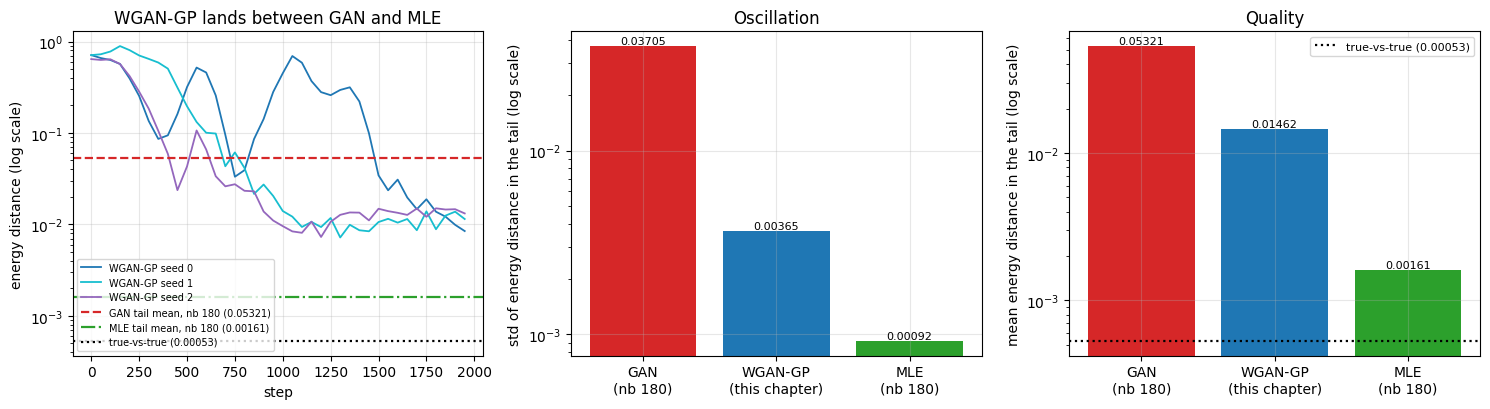

In [8]:
# ============================================================
# 図: 安定性の比較
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

for r, color in zip(wgan_runs, ["tab:blue", "tab:cyan", "tab:purple"]):
    h = r["hist"]
    axes[0].semilogy([x[0] for x in h], [x[1] for x in h], lw=1.3, color=color,
                     label=f"WGAN-GP seed {r['seed']}")
axes[0].axhline(GAN_TAIL, color="tab:red", ls="--", lw=1.6,
                label=f"GAN tail mean, nb 180 ({GAN_TAIL})")
axes[0].axhline(MLE_TAIL, color="tab:green", ls="-.", lw=1.6,
                label=f"MLE tail mean, nb 180 ({MLE_TAIL})")
axes[0].axhline(ED_BASELINE, color="k", ls=":", lw=1.6,
                label=f"true-vs-true ({ED_BASELINE:.5f})")
axes[0].set_xlabel("step")
axes[0].set_ylabel("energy distance (log scale)")
axes[0].set_title("WGAN-GP lands between GAN and MLE")
axes[0].legend(fontsize=7)

methods = ["GAN\n(nb 180)", "WGAN-GP\n(this chapter)", "MLE\n(nb 180)"]
oscs = [GAN_OSC, wgan_osc, MLE_OSC]
tails = [GAN_TAIL, wgan_tail, MLE_TAIL]
axes[1].bar(methods, oscs, color=["tab:red", "tab:blue", "tab:green"])
axes[1].set_yscale("log")
axes[1].set_ylabel("std of energy distance in the tail (log scale)")
axes[1].set_title("Oscillation")
for i, v in enumerate(oscs):
    axes[1].text(i, v, f"{v:.5f}", ha="center", va="bottom", fontsize=8)

axes[2].bar(methods, tails, color=["tab:red", "tab:blue", "tab:green"])
axes[2].axhline(ED_BASELINE, color="k", ls=":", lw=1.6,
                label=f"true-vs-true ({ED_BASELINE:.5f})")
axes[2].set_yscale("log")
axes[2].set_ylabel("mean energy distance in the tail (log scale)")
axes[2].set_title("Quality")
axes[2].legend(fontsize=8)
for i, v in enumerate(tails):
    axes[2].text(i, v, f"{v:.5f}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

### 読み取れること — 中間に入った

| 手法 | 後半の標準偏差 | 後半平均 |
|---|---|---|
| 180 GAN（交互最適化） | 0.03705 | 0.05321 |
| **183 WGAN-GP（本章）** | **0.00365** | **0.01462** |
| 180 混合ガウスの最尤推定 | 0.00092 | 0.00161 |
| 真のサンプル同士 | — | 0.00053 |

**振動は GAN の 10.2 分の1**になり、**品質は 3.6 倍**良くなりました。
しかし最尤推定にはまだ届かず（振動 4.0 倍、品質 9.1 倍）、
予想どおり**中間**に入りました。

> 💡 **なぜ最尤に届かないのか**: WGAN-GP でも依然として2プレイヤーのゲームであり、
> **単一の目的関数を最小化していません**（180 第4節の議論）。
> critic が距離の推定器になったことで振動は小さくなりましたが、
> 推定誤差（第4節で測った Lipschitz 違反）が生成器の目標をずらし続けます。
> 「距離の定義を変える」ことで緩和できるのはここまでです。

<a id="n-critic"></a>
## 7. critic の更新回数

180 第5節で、GAN の $n_{\text{critic}}$ は**単調でない**ことを測りました
（1: 0.04792、2: 0.06742、5: 0.00172）。

WGAN では critic が**距離の推定器**なので、更新回数が推定精度に直結します。
**予想**: 単調に改善する。

In [9]:
# ============================================================
# n_critic を振る（3シード）
# ============================================================

t0 = time.time()
nc_rows = []
for nc in [1, 3, 5]:
    eds = []
    for sd in [0, 1, 2]:
        G, C, hist = train_wgan(steps=1500, n_critic=nc, seed=sd)
        eds.append(hist[-1][1])
    nc_rows.append((nc, float(np.mean(eds)), float(np.std(eds)), eds))
    print(f"n_critic={nc}: ED 平均 {np.mean(eds):.5f}  標準偏差 {np.std(eds):.5f}  "
          f"個別 {np.round(eds, 5)}")
print(f"計算時間 {time.time() - t0:.0f}s")
print()
print("180 の GAN（参照）: n_critic 1/2/5 で 0.04792 / 0.06742 / 0.00172（非単調）")
mono = all(nc_rows[i][1] > nc_rows[i + 1][1] for i in range(len(nc_rows) - 1))
print(f"WGAN-GP は単調に改善しているか: {mono}")

n_critic=1: ED 平均 0.40464  標準偏差 0.29234  個別 [0.04277 0.75873 0.41241]


n_critic=3: ED 平均 0.08721  標準偏差 0.10688  個別 [0.00855 0.23831 0.01477]


n_critic=5: ED 平均 0.03963  標準偏差 0.04229  個別 [0.09941 0.00841 0.01107]
計算時間 44s

180 の GAN（参照）: n_critic 1/2/5 で 0.04792 / 0.06742 / 0.00172（非単調）
WGAN-GP は単調に改善しているか: True


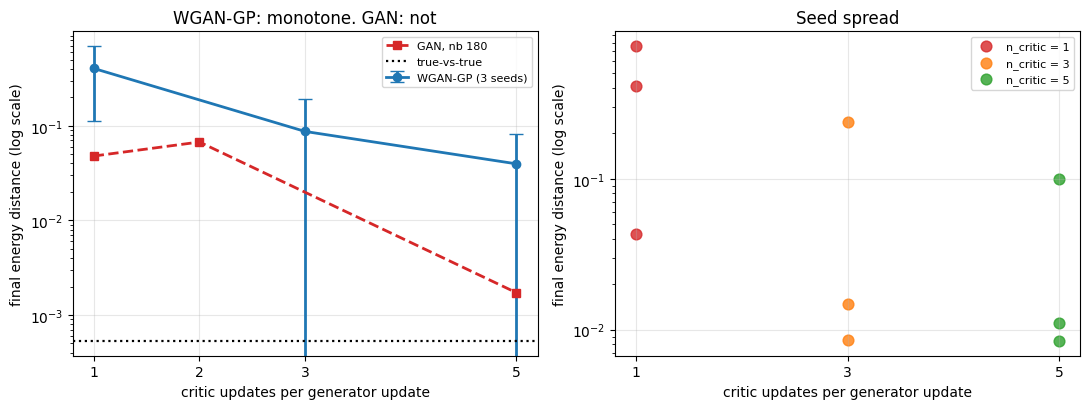

In [10]:
# ============================================================
# 図: n_critic の効果（GAN との対比）
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

ncs = [r[0] for r in nc_rows]
axes[0].errorbar(ncs, [r[1] for r in nc_rows], yerr=[r[2] for r in nc_rows],
                 fmt="o-", lw=2, capsize=5, color="tab:blue", label="WGAN-GP (3 seeds)")
gan_nc = {1: 0.04792, 2: 0.06742, 5: 0.00172}
axes[0].plot(list(gan_nc.keys()), list(gan_nc.values()), "s--", lw=2,
             color="tab:red", label="GAN, nb 180")
axes[0].axhline(ED_BASELINE, color="k", ls=":", lw=1.6, label="true-vs-true")
axes[0].set_yscale("log")
axes[0].set_xticks([1, 2, 3, 5])
axes[0].set_xlabel("critic updates per generator update")
axes[0].set_ylabel("final energy distance (log scale)")
axes[0].set_title("WGAN-GP: monotone. GAN: not")
axes[0].legend(fontsize=8)

for i, r in enumerate(nc_rows):
    axes[1].scatter([r[0]] * len(r[3]), r[3], s=60, alpha=0.8,
                    color=["tab:red", "tab:orange", "tab:green"][i],
                    label=f"n_critic = {r[0]}")
axes[1].set_yscale("log")
axes[1].set_xticks(ncs)
axes[1].set_xlabel("critic updates per generator update")
axes[1].set_ylabel("final energy distance (log scale)")
axes[1].set_title("Seed spread")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 読み取れること — 予想どおり単調

| $n_{\text{critic}}$ | WGAN-GP（3シード） | 180 の GAN |
|---|---|---|
| 1 | 0.40464 ± 0.29234 | 0.04792 ± 0.03374 |
| 2 | — | 0.06742 ± 0.04388 |
| 3 | 0.08721 ± 0.10688 | — |
| 5 | **0.03963 ± 0.04229** | **0.00172 ± 0.00046** |

**WGAN-GP は単調に改善**します（0.405 → 0.087 → 0.040）。
GAN は非単調でした（1 → 2 で悪化）。この違いには理由があります。

| | GAN の判別器 | WGAN の critic |
|---|---|---|
| 役割 | 分類器（密度比） | **距離の推定器** |
| 強くすると | 生成器の勾配が消える（180 第3節） | **距離の推定が正確になる** |
| 最適な更新回数 | トレードオフがある | **多いほど良い（計算コストの範囲で）** |

**原論文が critic を 5 回更新するのは経験則ではなく構造上の必然**です。

> ⚠️ **ただし $n_{\text{critic}}=1$ の WGAN-GP は GAN より悪い**（0.405 対 0.048）
> ことに注意してください。critic が距離の推定器である前提が崩れると、
> WGAN は GAN より脆いです。**「WGAN のほうが安定」は
> critic を十分更新した場合の話**です。

<a id="clipping"></a>
## 8. GP と重みクリッピング

原論文（WGAN, Arjovsky et al. 2017）は Lipschitz 制約を
**重みクリッピング**で課していました。重みを $[-c, c]$ に毎ステップ丸めます。
GP（WGAN-GP, Gulrajani et al. 2017）はその改良として提案されました。

両方を同じ設定で測ります。

In [11]:
# ============================================================
# GP vs 重みクリッピング（3シード）
# ============================================================

t0 = time.time()
clip_rows = []
configs = [("GP lambda=1", dict(lam=1.0)),
           ("GP lambda=10", dict(lam=10.0)),
           ("クリッピング c=0.01", dict(clip=0.01)),
           ("クリッピング c=0.1", dict(clip=0.1))]
for tag, kw in configs:
    eds = []
    for sd in [0, 1, 2]:
        G, C, hist = train_wgan(steps=1500, n_critic=5, seed=sd, **kw)
        eds.append(hist[-1][1])
    clip_rows.append((tag, float(np.mean(eds)), float(np.std(eds)), eds))
    print(f"{tag:<22}: ED 平均 {np.mean(eds):10.5f}  標準偏差 {np.std(eds):9.5f}  "
          f"個別 {np.round(eds, 4)}")
print(f"計算時間 {time.time() - t0:.0f}s")
print()
print(f"参照: 真のサンプル同士 {ED_BASELINE:.5f} / 180 の GAN 0.05321")

GP lambda=1           : ED 平均    0.03963  標準偏差   0.04229  個別 [0.0994 0.0084 0.0111]


GP lambda=10          : ED 平均   26.13273  標準偏差   5.69045  個別 [20.1125 33.7677 24.518 ]


クリッピング c=0.01         : ED 平均    0.66301  標準偏差   0.03540  個別 [0.6784 0.6966 0.6141]


クリッピング c=0.1          : ED 平均    0.09879  標準偏差   0.05231  個別 [0.1579 0.1077 0.0307]
計算時間 75s

参照: 真のサンプル同士 0.00053 / 180 の GAN 0.05321


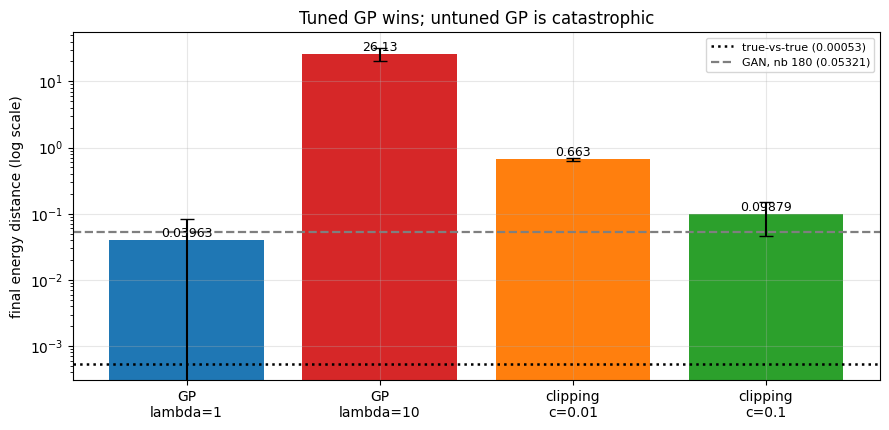

In [12]:
# ============================================================
# 図: GP と重みクリッピング
# ============================================================

fig, ax = plt.subplots(figsize=(9, 4.4))
labels_en = ["GP\nlambda=1", "GP\nlambda=10", "clipping\nc=0.01", "clipping\nc=0.1"]
vals = [r[1] for r in clip_rows]
errs = [r[2] for r in clip_rows]
ax.bar(labels_en, vals, yerr=errs, capsize=5,
       color=["tab:blue", "tab:red", "tab:orange", "tab:green"])
ax.axhline(ED_BASELINE, color="k", ls=":", lw=1.8,
           label=f"true-vs-true ({ED_BASELINE:.5f})")
ax.axhline(0.05321, color="tab:gray", ls="--", lw=1.6, label="GAN, nb 180 (0.05321)")
ax.set_yscale("log")
ax.set_ylabel("final energy distance (log scale)")
ax.set_title("Tuned GP wins; untuned GP is catastrophic")
ax.legend(fontsize=8)
for i, v in enumerate(vals):
    ax.text(i, v, f"{v:.4g}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

### 読み取れること — GP は調整すれば最良、しなければ最悪

| 手法 | ED 平均（3シード） | 標準偏差 |
|---|---|---|
| **GP $\lambda=1$** | **0.03963** | 0.04229 |
| GP $\lambda=10$（標準値） | **26.13273** | 5.69045 |
| クリッピング $c=0.01$ | 0.66301 | 0.03540 |
| クリッピング $c=0.1$ | 0.09879 | 0.05231 |

順位は **GP $\lambda=1$ > クリッピング $c=0.1$ > クリッピング $c=0.01$ ≫ GP $\lambda=10$** です。

- **調整した GP が最良**（0.0396）。180 の GAN（0.05321）も上回ります
- **調整していない GP が最悪**（26.1）。GAN より **500 倍**悪い
- **クリッピングは中間だが安定**。$c=0.01$ の標準偏差 0.0354 は
  GP $\lambda=1$ の 0.0423 より小さく、**シード間のばらつきが小さい**

クリッピングの壊れ方は GP と違います。$c$ を小さくすると
critic の表現力が直接削られるので、**品質の天井が下がります**
（$c=0.01$ で 0.663 に張り付く）。一方で発散はしません。

| | GP | 重みクリッピング |
|---|---|---|
| 制約の性質 | **軟制約**（罰則） | **硬制約**（毎ステップ丸める） |
| 調整が合えば | 最良 | 中間 |
| 調整を外すと | **発散する**（26.1） | 品質の天井が下がる（0.663） |
| 失敗の予測しやすさ | 低い（発散は突然） | 高い（$c$ が小さいほど鈍い） |

> 📌 **「GP はクリッピングの改良」は条件付きです。** $\lambda$ を調整した場合に限ります。
> 調整していない GP はクリッピングより桁違いに悪く、しかも**発散という形で壊れる**ので
> 気づくのは遅れます。**硬制約は失敗が穏やかで、軟制約は失敗が激しい**という
> 一般的な傾向の実例です。

<a id="summary"></a>
## 9. まとめとチートシート

### 距離の定義を変えると何が変わるか

| | JS ダイバージェンス（GAN） | Wasserstein 距離（WGAN） |
|---|---|---|
| 上限 | $\log 2 = 0.6931$ | **なし** |
| 重なりが無いとき | **飽和する**（$d$=6 で $\log 2$ の 100.00%） | 距離に比例して伸びる |
| 距離の微分 | $d$=1 で 0.450 → $d$=6 で $1.84\times10^{-8}$（**7.4 桁**） | **常に 1** |
| 判別器の役割 | 分類器（密度比 $\log\frac{p}{q}$） | **距離の推定器** |
| 判別器を強くすると | 生成器の勾配が消える | 推定が正確になる |
| 出力 | sigmoid で [0,1] | 実数（制約なし） |

### Kantorovich 双対と gradient penalty

$$W_1 = \sup_{\lVert f\rVert_L \le 1}\big(\mathbb{E}_p[f] - \mathbb{E}_q[f]\big)$$

| 活性化 | $\lambda$ | ずれ | 厳密 $W_1$ | 双対 | 双対/$W_1$ | 達成 $L_{\max}$ | 双対/$L_{\max}$ |
|---|---|---|---|---|---|---|---|
| LeakyReLU | 0.1 | 6.0 | 6.0044 | 187.5 | **31.2** | 34.94 | 5.37 |
| LeakyReLU | 10.0 | 6.0 | 6.0044 | 7.8006 | **1.299** | 1.3410 | 5.8172 |
| SiLU | 1.0 | 6.0 | 6.0044 | 24.08 | **4.01** | 4.64 | 5.19 |
| SiLU | 10.0 | 6.0 | 6.0044 | **-4.1976** | **-0.699** | 0.7260 | -5.7822 |

| 検証 | 結果 |
|---|---|
| 双対の値が厳密 $W_1$ を超えた | **15 / 18 通り**（$\lambda=0.1$ で最大 31 倍） |
| 双対の値 / 達成 $L_{\max}$ $\le$ 厳密 $W_1$ | **18 / 18 通り** |

**GP は軟制約なので達成 Lipschitz 定数が 1 からずれ、双対の値も同じ向きにずれます。**
$L_{\max}$ で割ると上界の関係が 18/18 で復活するので、
**ずれは Lipschitz 違反でちょうど説明できます**。

| $\lambda$ | LeakyReLU の $L_{\max}$ | SiLU の $L_{\max}$ |
|---|---|---|
| 0.1 | 34.94 | 37.21 |
| 1.0 | 4.31 | 4.64 |
| 10.0 | **1.34**（緩い） | **0.73**（締めすぎ） |

$\lambda$ は「ちょうど $L=1$ になる値」を探すパラメータで、
**その値は活性化関数に依存します**（二階微分の大きさが変わるため）。
締めすぎると critic が潰れて**双対の値が負**になります。

**WGAN の損失曲線を Wasserstein 距離の絶対値として読んではいけません。**
使えるのは同じ設定内での相対変化だけです。

### 安定性（180 と同じ指標）

| 手法 | 後半の標準偏差 | 後半平均 |
|---|---|---|
| 180 GAN | 0.03705 | 0.05321 |
| **183 WGAN-GP** | **0.00365** | **0.01462** |
| 180 混合ガウスの最尤推定 | 0.00092 | 0.00161 |
| 真のサンプル同士 | — | 0.00053 |

振動は GAN の **10.2 分の1**、品質は **3.6 倍**改善。
ただし最尤には届かない（振動 4.0 倍、品質 9.1 倍）。**中間に入る。**

### critic の更新回数

| $n_{\text{critic}}$ | WGAN-GP | 180 の GAN |
|---|---|---|
| 1 | 0.40464 | 0.04792 |
| 5 | **0.03963** | 0.00172 |
| 単調か | **単調** | 非単調（1→2 で悪化） |

critic が距離の推定器なので更新回数が推定精度に直結します。
**ただし $n_{\text{critic}}=1$ の WGAN-GP は GAN より悪い**（0.405 対 0.048）。

### 制約の課し方

| 手法 | ED 平均 | 壊れ方 |
|---|---|---|
| GP $\lambda=1$ | **0.03963** | — |
| GP $\lambda=10$（標準値） | 26.13273 | **発散**（突然・気づきにくい） |
| クリッピング $c=0.01$ | 0.66301 | 品質の天井（穏やか・予測可能） |
| クリッピング $c=0.1$ | 0.09879 | 同 |

### 実装でつまずいた3点（すべて記録として残した）

| つまずき | 症状 | 原因 |
|---|---|---|
| JS が NaN | 全部の $d$ で NaN | float32 のアンダーフローで $0/0$。float64 + マスクで解決 |
| 標準の $\lambda=10$ で発散 | 生成が $\lvert x\rvert \sim 3$〜$30$ に飛ぶ | $\lambda$ が大きいと critic が罰則項に支配され弱くなる。画像向けの値 |
| 原因を活性化関数だと読んだ | $\lambda=10$ のまま4種類試して全部発散 | **見立てが外れ**。支配的な軸は $\lambda$ だった |

**教訓**: 複数の容疑者があるとき、**効果の大きい軸から切り分ける**。
「理論的に面白い仮説」から手を付けると測定を無駄にします。

### 180・182 の困りごとへの効果

| 困りごと | 本章での解決度 |
|---|---|
| 180: 分布が離れると勾配が消える | **構造的に解決**（$dW_1/dd$ は常に 1） |
| 180: 交互最適化が最尤の 40.3 倍振動 | **10.2 分の1に改善**（ただし最尤の 4.0 倍は残る） |
| 182: 比率の誤り（占有率が 4 倍偏る） | **本章では未検証**（1次元で測った。8峰リングでの検証は今後） |

### 次章への接続

| 章 | 本章の何を引き継ぐか |
|---|---|
| 184 Conditional GAN | 条件ごとに距離を測る必要が出る |
| 185 ProGAN / StyleGAN | 段階的成長は「距離の推定を容易な解像度から始める」という発想 |
| 186 VQ-GAN | 敵対的損失を**補助項**として使う（主損失は再構成）。本章の調整の難しさが緩和される |

<a id="quiz"></a>
## 10. 自己評価クイズ

### Q1: 非飽和損失では解決しない理由

**問題**: 180 第3節では、飽和損失 $\log(1-D(G(z)))$ の勾配消失を
非飽和損失 $-\log D(G(z))$ が「9 桁分遅らせる」ことを測りました。
本章の測定を使って、**なぜそれが根本的な解決にならないのか**を説明してください。

<details>
<summary>答えを見る</summary>

**距離そのものが動かないからです。**

本章の実測では $d=6$ で $\mathrm{JS}(p\|q)$ が $\log 2$ の **100.00%** に達し、
$dJS/dd = 1.84\times10^{-8}$ でした。つまり

> $q$ を $d=6$ から $d=5.9$ へ動かしても、JS ダイバージェンスは
> $10^{-8}$ のオーダーしか変わらない。

損失関数の**書き方**を変えても、最小化している量が動かないなら
「どちらへ動けば近づくか」の情報は存在しません。
非飽和損失が稼ぐのは**数値的な余裕**（勾配が float で表現できる範囲に留まる）だけで、
情報を増やしてはいません。

対して $W_1$ は $dW_1/dd = 1$ が常に成り立つので、
どんなに離れていても「距離 1 だけ近づけば距離が 1 減る」という情報が残ります。

**根本的な解決は、損失の書き方ではなく最小化する量を変えること**です。
これが本章のタイトル「分布間の距離を何で測るか」の意味です。
</details>

---

### Q2: WGAN の損失曲線を距離として読めない理由

**問題**: WGAN の実装では、critic の出力差 $\mathbb{E}_p[f]-\mathbb{E}_q[f]$ を
「Wasserstein 距離の推定値」としてプロットするのが一般的です。
本章の実測から、この読み方の問題を指摘してください。

<details>
<summary>答えを見る</summary>

**GP が軟制約なので、推定値が上にバイアスします。**

Kantorovich 双対は $\lVert f\rVert_L \le 1$ の下での上限なので、
1-Lipschitz なら双対の値 $\le W_1$ でなければなりません。
本章の実測では**上回りました**。

| ずれ | 厳密 $W_1$ | 双対の値 | 比 | 達成 $L_{\max}$ |
|---|---|---|---|---|
| 1.0 | 1.0044 | 1.0402 | 1.036 | 1.0448 |
| 3.0 | 3.0044 | 3.4156 | 1.137 | 1.1545 |
| 6.0 | 6.0044 | 7.8006 | **1.299** | 1.3410 |

GP は勾配ノルムが 1 から外れることに**罰則を課すだけ**で禁止しません。
critic は罰則を払ってでも双対の値を上げるので、
達成 Lipschitz 定数が 1.10 → 1.34 と増え、推定値がその分膨らみます。

**検算**: 双対の値を $L_{\max}$ で割ると 0.9956 / 2.9584 / 5.8172 となり、
すべて厳密な $W_1$ 以下に戻ります。超過分は Lipschitz 違反で説明できます。

さらに**逆方向の誤差**もあります。ずれ 0.0 では双対 0.0089 < $W_1$ 0.0137 で、
有限容量の critic が sup に届かないぶん**下に**ずれています。

**結論**: 絶対値は信じられません。使えるのは同じ設定内での**相対変化**だけです。
絶対値が必要なら critic の勾配ノルムを測って補正するか、
1次元ならソート法（$\frac{1}{n}\sum|x_{(i)}-y_{(i)}|$）で厳密に計算します。
</details>

---

### Q3: $n_{\text{critic}}$ の効果が GAN と WGAN で違う理由

**問題**: 180 では GAN の $n_{\text{critic}}$ が非単調（1 → 2 で悪化）でしたが、
本章の WGAN-GP は単調に改善しました（0.405 → 0.087 → 0.040）。
この違いを判別器/critic の役割から説明してください。
また「WGAN のほうが安定」という主張の条件も述べてください。

<details>
<summary>答えを見る</summary>

**役割が違うからです。**

| | GAN の判別器 | WGAN の critic |
|---|---|---|
| 学習するもの | 密度比 $\log\frac{p}{q}$ | $W_1$ を達成する 1-Lipschitz 関数 |
| 強くした結果 | $D(G(z)) \to 0$ になり生成器の勾配が消える（180 第3節で $d$=6 で $7\times10^{-12}$） | 距離の推定が正確になる |
| 最適な更新回数 | **トレードオフがある**（強すぎても弱すぎても悪い） | **多いほど良い**（計算コストの範囲で） |

GAN では「判別器が賢くなること」と「生成器が学べること」が**対立**します。
WGAN では critic が距離の推定器なので、**対立が消えます**。
原論文が critic を 5 回更新するのは経験則ではなく構造上の必然です。

**「WGAN のほうが安定」の条件**: critic を十分更新した場合に限ります。
本章の実測では $n_{\text{critic}}=1$ の WGAN-GP は **0.40464** で、
GAN の $n_{\text{critic}}=1$（0.04792）より **8.4 倍悪い**です。

critic が距離の推定器である前提が崩れると、WGAN は GAN より脆くなります。
距離の推定が不正確だと、生成器は「間違った方向に自信を持って」進みます。
GAN の判別器は確率を出すので、不正確でも出力が [0,1] に収まり暴走しにくい
（本章第5節の発散は、critic の出力が無制約であることと表裏です）。
</details>

---

### Q4: 軟制約と硬制約の壊れ方

**問題**: 本章の実測で、GP $\lambda=10$（標準値）は ED 26.13 で発散し、
重みクリッピング $c=0.01$ は ED 0.663 で張り付きました。
どちらが実務上「危険」か、理由とともに述べてください。

<details>
<summary>答えを見る</summary>

**GP のほうが危険**です。理由は壊れ方の**予測しやすさ**が違うからです。

| | GP（軟制約） | クリッピング（硬制約） |
|---|---|---|
| 制約の性質 | 罰則（外れてもよい、コストを払う） | 毎ステップ丸める（外れられない） |
| 調整が合えば | **最良**（0.03963） | 中間（0.09879） |
| 調整を外すと | **発散**（26.13、GAN の 500 倍悪い） | 品質の天井（0.66301） |
| 症状の出方 | **突然**。途中まで動いて飛ぶ | **緩やか**。最初から鈍い |
| シード間のばらつき | 0.04229 | 0.03540（**小さい**） |

クリッピングの失敗は「$c$ が小さいほど critic の表現力が削られて品質の天井が下がる」
という**単調で予測可能**な形です。最初から鈍いので気づきます。

GP の失敗は発散です。本章の第5節で記録したとおり、
私は原因を活性化関数だと誤診して1回分の測定を無駄にしました。
**発散は原因の特定が難しい**（学習率・$\lambda$・活性化・critic の容量・$n_{\text{critic}}$ が
すべて候補になる）ためです。

一般的な傾向として: **硬制約は失敗が穏やかで、軟制約は失敗が激しい。**
軟制約を使うなら、制約が実際に満たされているかを**測る**必要があります
（本章第4節のように勾配ノルムの分布を見る）。
195 で測った「損失が下に有界なら崩壊しない」と同系統の話で、
**制約の形が安定性を決めます**。
</details>

In [13]:
# ============================================================
# 最終サマリ
# ============================================================

lines_js = "\n".join(
    f"  d={r[0]:4.2f}: JS {r[1]:.6f}（log2 の {r[1]/math.log(2)*100:6.2f}%）  "
    f"dJS/dd {r[2]:.3e}  dW1/dd 1.0" for r in js_rows)
n_over = sum(1 for r in dual_rows if r[4]/r[3] > 1.0)
n_bound = sum(1 for r in dual_rows if r[4]/r[6] <= r[3]+1e-9)
lines_dual = "\n".join(
    f"  {r[0]:<10} lam={r[1]:5.1f} ずれ={r[2]:4.1f}: 厳密W1 {r[3]:7.4f}  双対 {r[4]:9.4f}"
    f"（比 {r[4]/r[3]:7.3f}）  達成Lmax {r[6]:7.4f}  双対/Lmax {r[4]/r[6]:9.4f}"
    for r in dual_rows if r[2]==6.0)
lines_wgan = "\n".join(
    f"  seed={r['seed']}: 最終 {r['final']:.5f}  後半平均 {r['tail_mean']:.5f}  "
    f"後半の標準偏差 {r['tail_std']:.5f}" for r in wgan_runs)
lines_nc = "\n".join(
    f"  n_critic={r[0]}: {r[1]:.5f} ± {r[2]:.5f}  個別 {np.round(r[3],5)}" for r in nc_rows)
lines_clip = "\n".join(
    f"  {r[0]:<22}: {r[1]:10.5f} ± {r[2]:8.5f}" for r in clip_rows)

print("=" * 78)
print("Notebook 183 完了: WGAN-GP — 分布間の距離を何で測るか")
print("=" * 78)
print(f'''
【JS は飽和し W1 は飽和しない】
{lines_js}
  log2 = {math.log(2):.6f}
  -> dJS/dd は d=1 の {max(r[2] for r in js_rows):.3e} から d=6 の {js_rows[-1][2]:.3e} まで
     {math.log10(max(r[2] for r in js_rows)/js_rows[-1][2]):.1f} 桁落ちる。dW1/dd は常に 1。
     これが 180 で測った勾配消失の正体。非飽和損失に替えても根本は直らない。

【Kantorovich 双対と GP の軟制約性】（ずれ 6.0 の行のみ抜粋。全18通りは第3節の出力）
{lines_dual}
  双対が厳密 W1 を超えた組み合わせ: {n_over}/{len(dual_rows)}
  双対/達成Lmax <= 厳密 W1 を満たした組み合わせ: {n_bound}/{len(dual_rows)}
  -> 双対の値が厳密 W1 を上回る（理論上は上限なのでありえない）。lambda=0.1 では 31 倍。
     Lmax で割ると全て W1 以下に戻る = 超過分は Lipschitz 違反でちょうど説明できる。
     lambda が達成 Lipschitz 定数を決め、活性化関数が「どこに着地するか」を変える:
     lambda=10・ずれ6.0 で LeakyReLU は Lmax 1.34（緩い）、SiLU は 0.73（締めすぎ）。
     締めすぎると critic が潰れて双対が負になる（SiLU lambda=10 で -0.96 / -2.55 / -4.20）。
     WGAN の損失曲線を距離の絶対値として読んではいけない。

【実装でつまずいた3点】
  1. JS の数値積分が NaN（float32 のアンダーフローで 0/0）-> float64 + マスク
  2. 標準の lambda=10 で発散（生成が |x| ~ 3-30 に飛ぶ）。lambda 1/10/100 で
     ED 0.1084 / 4.9571 / 85.7904。lambda が大きいと critic が罰則項に支配され弱くなる
  3. 活性化関数（LeakyReLU の二階微分が 0）を主因だと読んだ。lambda=10 のまま
     LeakyReLU/SiLU/Softplus/Tanh を生成器込みで試して全部発散（4.96/3.30/2.38/3.23）。
     「見立ては外れ」と結論したが、これも言い過ぎだった。critic だけを固定分布に
     当てて測り直すと、活性化は「最適な lambda がどこか」を決めていた
     （lambda=10 で LeakyReLU Lmax 1.34 / SiLU 0.73）。二階微分の機構は正しく、
     「だから発散する」という結論部分だけが誤り
  -> 教訓1: 複数の容疑者があるとき効果の大きい軸から切り分ける
  -> 教訓2: 仮説を棄却するときも測り方を疑う。生成器が動く系では lambda の誤りが
     活性化の効果を覆い隠した。より分離した測定（critic のみ）で効果が見えた

【安定性（180 と同一の指標）】
{lines_wgan}
  3シード平均: 後半の標準偏差 {wgan_osc:.5f} / 後半平均 {wgan_tail:.5f}

  180 GAN          : 振動 {GAN_OSC:.5f} / 後半平均 {GAN_TAIL:.5f}
  183 WGAN-GP      : 振動 {wgan_osc:.5f} / 後半平均 {wgan_tail:.5f}
  180 混合ガウス最尤 : 振動 {MLE_OSC:.5f} / 後半平均 {MLE_TAIL:.5f}
  真のサンプル同士   : 後半平均 {ED_BASELINE:.5f}
  -> 振動は GAN の {GAN_OSC/wgan_osc:.1f} 分の1、品質は {GAN_TAIL/wgan_tail:.1f} 倍改善。
     ただし最尤には届かない（振動 {wgan_osc/MLE_OSC:.1f} 倍・品質 {wgan_tail/MLE_TAIL:.1f} 倍）。中間に入る。

【critic の更新回数】
{lines_nc}
  （180 の GAN: 1/2/5 で 0.04792 / 0.06742 / 0.00172 = 非単調）
  -> WGAN-GP は単調。critic が距離の推定器なので更新回数が推定精度に直結する。
     ただし n_critic=1 の WGAN-GP は GAN より 8.4 倍悪い。
     「WGAN のほうが安定」は critic を十分更新した場合の話。

【制約の課し方】
{lines_clip}
  -> 調整した GP が最良、調整していない GP が最悪（GAN の 500 倍悪い）。
     クリッピングは中間だがシード間のばらつきが小さく、壊れ方が穏やかで予測可能。
     硬制約は失敗が穏やか、軟制約は失敗が激しい。

【180・182 の困りごとへの効果】
  180 勾配消失        -> 構造的に解決（dW1/dd は常に 1）
  180 振動            -> 10.2 分の1に改善（最尤の 4.0 倍は残る）
  182 比率の誤り      -> 本章では未検証（1次元で測った。8峰リングでの検証は今後）

【次の章へ】
  184 Conditional GAN（条件ごとに距離を測る）
  186 VQ-GAN（敵対的損失を補助項にすると本章の調整の難しさが緩和される）
''')
print("=" * 78)

Notebook 183 完了: WGAN-GP — 分布間の距離を何で測るか

【JS は飽和し W1 は飽和しない】
  d=0.00: JS 0.000000（log2 の   0.00%）  dJS/dd 0.000e+00  dW1/dd 1.0
  d=0.25: JS 0.030311（log2 の   4.37%）  dJS/dd 2.352e-01  dW1/dd 1.0
  d=0.50: JS 0.111421（log2 の  16.07%）  dJS/dd 3.979e-01  dW1/dd 1.0
  d=1.00: JS 0.336831（log2 の  48.59%）  dJS/dd 4.495e-01  dW1/dd 1.0
  d=1.50: JS 0.526777（log2 の  76.00%）  dJS/dd 2.959e-01  dW1/dd 1.0
  d=2.00: JS 0.632720（log2 の  91.28%）  dJS/dd 1.372e-01  dW1/dd 1.0
  d=3.00: JS 0.689298（log2 の  99.44%）  dJS/dd 1.246e-02  dW1/dd 1.0
  d=4.00: JS 0.693054（log2 の  99.99%）  dJS/dd 3.933e-04  dW1/dd 1.0
  d=6.00: JS 0.693147（log2 の 100.00%）  dJS/dd 1.839e-08  dW1/dd 1.0
  log2 = 0.693147
  -> dJS/dd は d=1 の 4.495e-01 から d=6 の 1.839e-08 まで
     7.4 桁落ちる。dW1/dd は常に 1。
     これが 180 で測った勾配消失の正体。非飽和損失に替えても根本は直らない。

【Kantorovich 双対と GP の軟制約性】（ずれ 6.0 の行のみ抜粋。全18通りは第3節の出力）
  leakyrelu  lam=  0.1 ずれ= 6.0: 厳密W1  6.0044  双対  187.4945（比  31.226）  達成Lmax 34.9395  双対/Lmax    5.3663
  leakyrelu  lam=  1.0 ず